In [ ]:
from getpass import getpass

kaggle_token = getpass("The Token is")

The Token is··········


In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

In [ ]:
!kaggle datasets download \
    -d tatheerabbas/synthetic-industrial-metal-surface-defects \
    -p /content/data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/tatheerabbas/synthetic-industrial-metal-surface-defects
License(s): Attribution 4.0 International (CC BY 4.0)
100% 360M/360M [00:03<00:00, 96.1MB/s]



In [ ]:
import tensorflow as tf

IMG_SIZE = (256, 256)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data/industrial_defect_dataset/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42,
    color_mode="grayscale",
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data/industrial_defect_dataset/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    color_mode="grayscale",
    label_mode="int"
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 12000 files belonging to 5 classes.
Found 3000 files belonging to 5 classes.
Classes: ['crack', 'hole', 'normal', 'rust', 'scratch']


In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 256, 256, 1)
Label batch shape: (32,)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 247.0
First 10 labels: [3 0 3 3 3 1 3 4 2 4]


In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)
val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

In [ ]:
for images, labels in train_ds.take(1):
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())

Minimum: 0.0
Maximum: 0.96470594


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(256,256,1)),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu',padding='same'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu',padding='same'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(5, activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,781 (108.52 KB)

 Trainable params: 27,781 (108.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
!nvidia-smi

Sat Oct 31 15:02:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P0             27W /   70W |     117MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 62ms/step - accuracy: 0.2760 - loss: 1.5572 - val_accuracy: 0.3123 - val_loss: 1.4400
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.3687 - loss: 1.3862 - val_accuracy: 0.3973 - val_loss: 1.3178
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.4218 - loss: 1.2684 - val_accuracy: 0.4533 - val_loss: 1.1978
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.4938 - loss: 1.1401 - val_accuracy: 0.5897 - val_loss: 1.0536
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 60ms/step - accuracy: 0.5826 - loss: 1.0147 - val_accuracy: 0.6603 - val_loss: 0.8971
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 60ms/step - accuracy: 0.7103 - loss: 0.7838 - val_accuracy: 0.7667 - val_loss: 0.6476
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 23s 60ms/step - accuracy: 0.7853 - loss: 0.6029 - val_accuracy: 0.8460 - val_loss: 0.4916
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.8362 - loss: 0.5033 - 

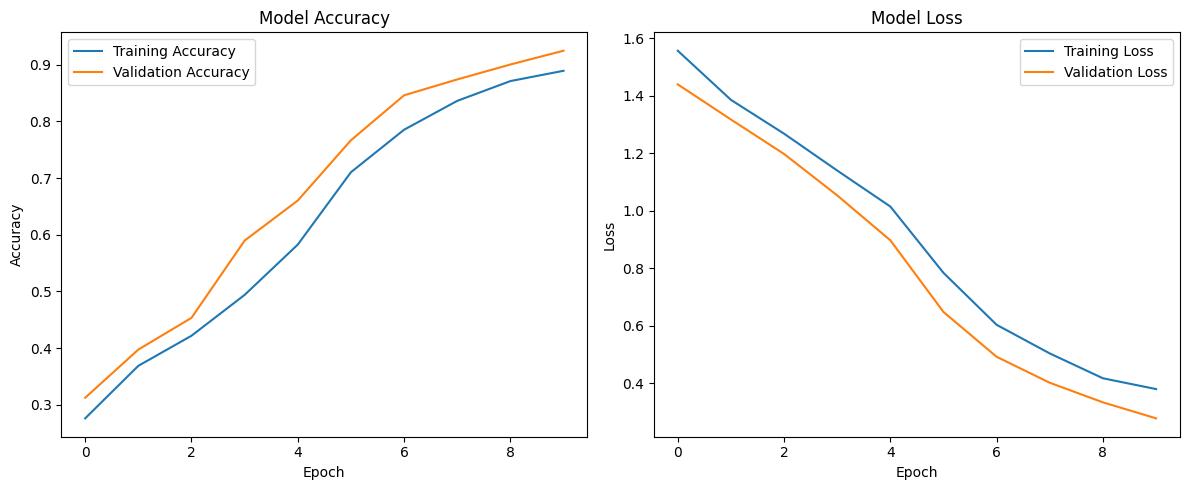

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()